# Kumbuka ML engine (Project Deliverable 2 / CAT 2): can a trained model guess memory better than a hand-written rule?

**Group:** BICS 3E  |  **Unit:** ICS 3202 Artificial Intelligence  |  **Dataset:** Duolingo half-life regression release (Settles & Meeder, 2016)

## The question in plain words
Kumbuka has to decide which topics you should revise today. To do that it needs a guess for each topic: *how likely am I to still remember this right now?*

We compare two ways of making that guess:

| | What it is | Where its numbers come from |
|---|---|---|
| **Baseline (the rule)** | Assumes you forget half of a topic in about 4 days, a bit slower if you did well last time. This is the hand-set `placeholder-v1` rule already in the Kumbuka app. | Someone picked them by hand. |
| **Model (half-life regression)** | A *regression* (a method that learns a number from examples) that learns how fast memory fades from 13 million real review records. | Learned from data. |

**H0 (null hypothesis):** the trained model guesses memory no better than the hand-written rule.
**H1:** the trained model guesses memory better.

We test this on reviews from **learners the model has never seen**, so it cannot win by memorising people.

**How this notebook follows the CAT 2 brief**

| Brief item | Where it is |
|---|---|
| 1. ML approach and algorithm | Section "ML approach" just below |
| 2. Data cleaning and EDA (4+ observations) | Step 2 (Observations 1 to 4) |
| 3. Base model with validity checks | Steps 3 to 7 (learner-held-out split, ridge strength chosen by cross-validation, bootstrap) |
| 4. Other methods to validate the base model | Step 8 (described, to be built for the final notebook) |

## ML approach (brief item 1)
- **Kind of learning:** *supervised regression*. We have examples with a known answer (how much was recalled) and the model learns to predict that number.
- **Base algorithm:** *half-life regression* (Settles & Meeder, 2016), fitted with *ridge regression*. Ridge is ordinary regression with a penalty that stops the learned numbers getting extreme.
- **What goes in:** days since the topic was last reviewed, and how many times it was answered right and wrong before.
- **What comes out:** a number from 0 to 1, the chance you still remember the topic right now. Kumbuka sorts topics by this number.
- **Compared against:** a hand-written rule (the baseline) and "always guess the average".
- **Planned extra comparators (Step 8):** logistic regression and a random forest.

## Step 1: Load the dataset *(Person A)*
Same file as Deliverable 1 (Harvard Dataverse, `doi:10.7910/DVN/N8XJME/UEPJVH`). Each row is one learner practising one word in one session.
The file has 12 columns. We first get all of them, then load only the five we need to ensure colabs memory is sufficient.

In [1]:
import os
import numpy as np
import pandas as pd

FILE = "learning_traces.csv.gz"
if not os.path.exists(FILE):
    !wget -q -O {FILE} "https://dataverse.harvard.edu/api/access/datafile/:persistentId?persistentId=doi:10.7910/DVN/N8XJME/UEPJVH"

print("All columns in the file:", list(pd.read_csv(FILE, nrows=5).columns))

use = ["p_recall", "delta", "user_id", "history_seen", "history_correct"]
df = pd.read_csv(FILE, usecols=use, dtype={"user_id": "category"})
print(df.shape)
df.head()

All columns in the file: ['p_recall', 'timestamp', 'delta', 'user_id', 'learning_language', 'ui_language', 'lexeme_id', 'lexeme_string', 'history_seen', 'history_correct', 'session_seen', 'session_correct']


(12854226, 5)


,p_recall,delta,user_id,history_seen,history_correct
0,1.0,27649635,u:FO,6,4
1,0.5,27649635,u:FO,4,4
2,1.0,27649635,u:FO,5,4
3,0.5,27649635,u:FO,6,5
4,1.0,27649635,u:FO,4,4


**What the columns mean**
- `p_recall`: the share of this word's answers that were right *in this session* (0, 0.5 or 1 for most rows). This is what we try to predict.
- `delta`: seconds since the learner last practised this word.
- `history_seen` / `history_correct`: how many times the learner had seen the word before, and how many of those they got right.
- `user_id`: who the learner is. We use it to keep people from leaking between training and testing.

So we can see what wont be here : Theres nothing about what the word means. Duolingo's model never reads the content, only timing and past results. Kumbuka records exactly those things for a topic like "Learning Agents", which is why this model can transfer.

**Columns we leave out, and why**
- `timestamp`: when the session happened. Kumbuka works from *gaps* between reviews, which `delta` already gives us.
- `lexeme_id`, `lexeme_string`, `learning_language`, `ui_language`: they say *which word* and *which language*. A university topic has neither, and a model that leaned on them could not run inside the app.
- `session_seen`, `session_correct`: the counts inside the session being predicted. `p_recall` is built from them, so using them would be like peeking at the answer.

## Step 2: Explore and clean *(Person A)*
We go in this order: (a) check the whole file for missing values, impossible values and duplicates (steps 1, 3 and 5 of the course's data-cleaning recipe), (b) take a fixed random sample, (c) look at extreme values (step 6, outliers), (d) build the model inputs, (e) read four observations off the data, (f) summarise the final dataset.

**(a) Missing values, impossible values and duplicates, on all 12.8 million rows.** Each check prints how many rows break the rule. Rows that break one are dropped. Duplicates are removed with `drop_duplicates()`, as in the course notes ("remove all duplicate values"). Two rows can look identical without being the same event, because the word column is gone, so we report how many were removed and show that the result barely changes.

In [2]:
print("Missing values per column:")
print(df.isnull().sum())

rules = {
    "history_correct > history_seen (cannot get more right than you saw)": df["history_correct"] > df["history_seen"],
    "history_seen < 1 (no history, rule and model have nothing to use)":     df["history_seen"] < 1,
    "negative delta (time cannot run backwards)":                           df["delta"] < 0,
    "p_recall outside 0..1":                                                ~df["p_recall"].between(0, 1),
}
bad = pd.Series(False, index=df.index)
for name, mask in rules.items():
    print(f"{mask.sum():>10,}  rows: {name}")
    bad |= mask

rows_before = len(df)
df = df[~bad]
print(f"\nDropped {bad.sum():,} rows. Kept {len(df):,} of {rows_before:,}.")

# course step 1: scrub for duplicates
rows_after_bad = len(df)
n_dup = int(df.duplicated().sum())
print(f"Exact duplicate rows: {n_dup:,} ({n_dup / rows_after_bad:.1%} of the file)")
df = df.drop_duplicates()
print(f"After drop_duplicates(): {len(df):,} rows")

Missing values per column:
p_recall           0
delta              0
user_id            0
history_seen       0
history_correct    0
dtype: int64


         0  rows: history_correct > history_seen (cannot get more right than you saw)
         0  rows: history_seen < 1 (no history, rule and model have nothing to use)
         0  rows: negative delta (time cannot run backwards)
         0  rows: p_recall outside 0..1

Dropped 0 rows. Kept 12,854,226 of 12,854,226.


Exact duplicate rows: 1,717,691 (13.4% of the file)


After drop_duplicates(): 11,136,535 rows


**(b) Sample.** We use 1 million random rows with a fixed seed (`random_state=42`), so everyone gets identical results. The full file is more than the model needs: it has only a handful of numbers to learn.

**(c) Extreme values (outliers).** The course says to detect them with a boxplot, then drop or fix them if they come from errors. We draw the boxplots first, then decide.

Extreme values (99th percentile vs maximum):
  t_days           99th pct =     132.87   max =     460.17
  history_correct  99th pct =     235.00   max =   12877.00
  history_wrong    99th pct =      29.00   max =    2436.00


  t_days           13.8% of rows sit above the boxplot whisker (13.3)
  history_correct  11.1% of rows sit above the boxplot whisker (33.0)
  history_wrong    7.6% of rows sit above the boxplot whisker (5.0)


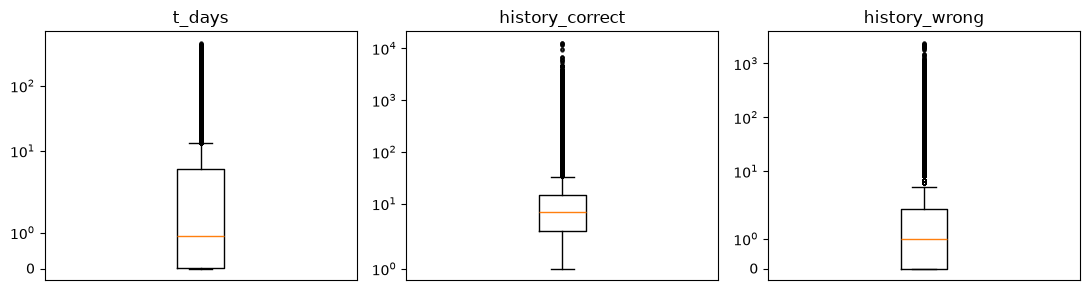

In [3]:
SEED = 42
H_MIN, H_MAX = 15 / (60 * 24), 274.0          # days: 15 minutes .. 274 days

d = df.sample(n=1_000_000, random_state=SEED).copy()
d["user_id"] = d["user_id"].astype(str)
d["t_days"] = d["delta"] / 86400.0
d["history_wrong"] = d["history_seen"] - d["history_correct"]

print("Extreme values (99th percentile vs maximum):")
for col in ["t_days", "history_correct", "history_wrong"]:
    print(f"  {col:16s} 99th pct = {d[col].quantile(0.99):10.2f}   max = {d[col].max():10.2f}")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a_, col in zip(ax, ["t_days", "history_correct", "history_wrong"]):
    a_.boxplot(d[col], showfliers=True, flierprops={"markersize": 2, "alpha": 0.3})
    a_.set_yscale("symlog"); a_.set_title(col); a_.set_xticks([])
    q1, q3 = d[col].quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
    print(f"  {col:16s} {(d[col] > upper).mean():.1%} of rows sit above the boxplot whisker ({upper:.1f})")
plt.tight_layout(); plt.show()

**Decision on extreme values: keep them.** The boxplots show a long tail of points past the whiskers, which is what skewed counts look like. The course treats outliers as problems *caused by errors in data collection*. A learner who has seen a word 12,000 times, or one who returns after 460 days, is real behaviour, not a typing mistake, so we do not delete them or replace them with the mean. The model uses *square roots* of the counts, which tames big numbers, and the half-life target is capped (next cell), which tames big gaps.

**(d) Build the inputs and the target.** The half-life is how many days until you have a 50/50 chance of remembering. From a recall probability *p* after *t* days it is `h = -t / log2(p)`. A recall of exactly 0 or 1 gives an infinite or zero half-life, so, as in the Duolingo paper, we clip *p* to [0.0001, 0.9999] and *h* to between 15 minutes and 274 days.

In [4]:
d["recalled"] = (d["p_recall"] >= 0.5).astype(int)   # yes/no label, used for AUC

p_clip = d["p_recall"].clip(0.0001, 0.9999)
d["h_true"] = (-d["t_days"] / np.log2(p_clip)).clip(H_MIN, H_MAX)

print(d[["p_recall", "t_days", "history_correct", "history_wrong", "h_true"]].describe().round(3))
print("Share of rows recalled (>=0.5):", round(d["recalled"].mean(), 3))

          p_recall       t_days  history_correct  history_wrong       h_true
count  1000000.000  1000000.000      1000000.000    1000000.000  1000000.000
mean         0.883        8.616           21.760          2.996      154.610
std          0.286       26.255          122.206         28.447      124.583
min          0.000        0.000            1.000          0.000        0.010
25%          1.000        0.006            3.000          0.000       17.809
50%          1.000        0.917            7.000          1.000      274.000
75%          1.000        5.327           15.000          2.000      274.000
max          1.000      460.166        12877.000       2436.000      274.000
Share of rows recalled (>=0.5): 0.918


**(e) Four observations from the data.** Each cell below shows the evidence, and the line under it says what it means for the model.

Observation 1: 50.2% of the half-life targets sit exactly at the 274-day cap.
Half-life quantiles (days): {0.1: 0.5, 0.25: 17.8, 0.5: 274.0, 0.75: 274.0, 0.9: 274.0}


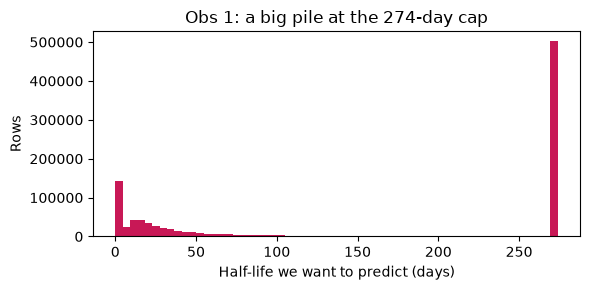

In [5]:
import matplotlib.pyplot as plt

capped = (d["h_true"] >= H_MAX).mean()
print(f"Observation 1: {capped:.1%} of the half-life targets sit exactly at the {H_MAX:.0f}-day cap.")
print("Half-life quantiles (days):", d["h_true"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_dict())

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(d["h_true"], bins=60, color="#C81856")
ax.set_xlabel("Half-life we want to predict (days)"); ax.set_ylabel("Rows")
ax.set_title("Obs 1: a big pile at the 274-day cap")
plt.tight_layout(); plt.show()

**Observation 1: about half (50%) of the half-life targets are stuck at the 274-day ceiling.** The learner got the word right, so we cannot tell how long the memory would really last, only that it lasted at least that long. The model has to learn from a target that is "clipped" for most rows, which is one reason its scores are modest. *(The brief's EDA asks for critical observations: this is the one that changes how much we should trust the model.)*

Observation 2:
recalled
remembered    0.918
forgot        0.082
Name: proportion, dtype: float64


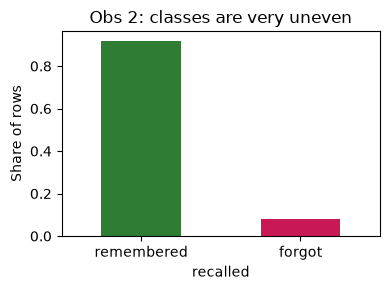

In [6]:
counts = d["recalled"].value_counts(normalize=True).rename({1: "remembered", 0: "forgot"})
print("Observation 2:")
print(counts.round(3))

fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax, color=["#2E7D32", "#C81856"], rot=0)
ax.set_ylabel("Share of rows"); ax.set_title("Obs 2: classes are very uneven")
plt.tight_layout(); plt.show()

**Observation 2: about 92% of rows are "remembered".** The classes are very uneven. A lazy guesser that always says "remembered" is right 92% of the time, which is why we judge with MAE and AUC (and compare against "always guess the average") instead of plain accuracy.

Observation 3: days since last review
count    1000000.000
mean           8.616
std           26.255
min            0.000
25%            0.006
50%            0.917
75%            5.327
90%           20.140
99%          132.867
max          460.166
Name: t_days, dtype: float64
Share of reviews within 1 day of the last one: 52.5%


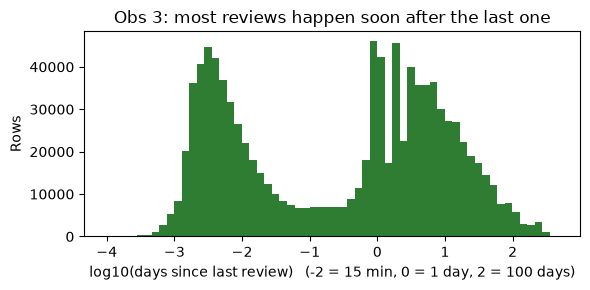

In [7]:
print("Observation 3: days since last review")
print(d["t_days"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(3))
print(f"Share of reviews within 1 day of the last one: {(d['t_days'] < 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(np.log10(d["t_days"].clip(lower=1e-4)), bins=60, color="#2E7D32")
ax.set_xlabel("log10(days since last review)   (-2 = 15 min, 0 = 1 day, 2 = 100 days)")
ax.set_ylabel("Rows"); ax.set_title("Obs 3: most reviews happen soon after the last one")
plt.tight_layout(); plt.show()

**Observation 3: the typical (median) gap is about 0.9 days, and 52% of reviews happen within a day of the last.** Duolingo learners practise in bursts. A student revising for a university exam leaves *days or weeks* between reviews, so the model is being asked about longer gaps than most of what it learned from. This feeds the transfer limit in Step 10.

Observation 4: how much history learners have (before this review)
       history_seen  history_correct  history_wrong
count     1000000.0        1000000.0      1000000.0
mean           24.8             21.8            3.0
std           140.6            122.2           28.4
min             1.0              1.0            0.0
50%             7.0              7.0            1.0
90%            41.0             37.0            4.0
99%           269.0            235.0           29.0
max         13506.0          12877.0         2436.0



Learners in the sample: 88,134
Top 1% of learners supply 14.7% of the rows


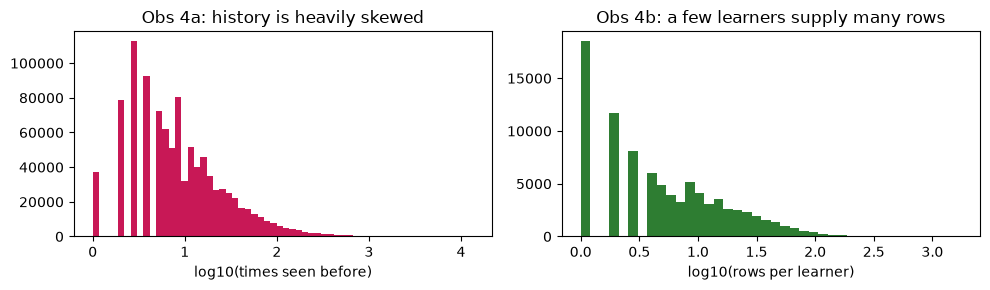

In [8]:
print("Observation 4: how much history learners have (before this review)")
print(d[["history_seen", "history_correct", "history_wrong"]].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

per_user = d.groupby("user_id").size().sort_values(ascending=False)
print(f"\nLearners in the sample: {len(per_user):,}")
print(f"Top 1% of learners supply {per_user.head(max(1, len(per_user)//100)).sum() / len(d):.1%} of the rows")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(np.log10(d["history_seen"].clip(lower=1)), bins=60, color="#C81856")
ax[0].set_xlabel("log10(times seen before)"); ax[0].set_title("Obs 4a: history is heavily skewed")
ax[1].hist(np.log10(per_user.values), bins=40, color="#2E7D32")
ax[1].set_xlabel("log10(rows per learner)"); ax[1].set_title("Obs 4b: a few learners supply many rows")
plt.tight_layout(); plt.show()

**Observation 4: history counts and rows-per-learner are both extremely right-skewed.** Most records have a short history, and a minority of heavy users have thousands (the top 1% of learners supply about 15% of the rows). That is why we use square roots of the counts, and why we split train and test by *learner* in Step 3: a few heavy users could otherwise dominate both piles.

**(f) The final dataset used for modelling**

In [9]:
print(f"Rows in the file:            {rows_before:,}")
print(f"After removing bad rows:     {len(df):,}")
print(f"Random sample used:          {len(d):,}  (seed {SEED})")
print("Inputs to the model:         t_days, history_correct, history_wrong")
print("Target (regression):         h_true, the half-life in days, from p_recall")
print("Label (for AUC only):        recalled = p_recall >= 0.5")
print("Missing values left:        ", int(d[["p_recall", "t_days", "history_correct", "history_wrong"]].isnull().sum().sum()))

Rows in the file:            12,854,226
After removing bad rows:     11,136,535
Random sample used:          1,000,000  (seed 42)
Inputs to the model:         t_days, history_correct, history_wrong
Target (regression):         h_true, the half-life in days, from p_recall
Label (for AUC only):        recalled = p_recall >= 0.5
Missing values left:         0


## Step 3: Split by learner, not by row *(Person A)*
If we split rows at random, the same person's history lands in both piles and the model looks smarter than it is. So we split **by learner**: 80% of learners to teach the model (*training*), 20% held back to test it (*testing*). The check below proves no learner appears in both.

In [10]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(d, groups=d["user_id"]))
train, test = d.iloc[train_idx], d.iloc[test_idx]

overlap = set(train["user_id"]) & set(test["user_id"])
print("train rows:", len(train), "| test rows:", len(test))
print("learners in both piles:", len(overlap))
assert len(overlap) == 0

train rows: 798301 | test rows: 201699
learners in both piles: 0


## Step 4: The two baselines *(Person B)*
**(a) The hand-written rule.** A Python copy of the app's `PlaceholderRecallPredictor`: half-life = 4 days × (1 + rating ÷ 3), and recall = 0.5^(days ÷ half-life). In the app, *rating* is the student's last self-rating (0 to 3). Duolingo has no self-rating, so we stand in **past accuracy × 3** (a learner who got 100% right counts as rating 3). This substitution is a stated assumption, not a fact.

**Which "rule" is this?** It is the app's `placeholder-v1` recall guess. It is *not* the weighted study-priority score in `DESIGN.md` section 4 (gap, staleness, urgency, avoidance), because that score ranks topics using exam dates and avoidance, which Duolingo data does not have, so it cannot be tested here. It is also a weak baseline: its 4-day half-life is far too short for this data, which is why it later scores worse than guessing the average. So "the model beats the rule" is a low bar, and "the model beats the average guess" (a small win) is the fairer test.

**(b) "Always guess the average."** The laziest possible guess. Any real method must beat it.

In [11]:
def rule_predict(frame):
    rating = 3.0 * frame["history_correct"] / frame["history_seen"]      # stand-in for the 0..3 self-rating
    half_life = 4.0 * (1.0 + rating / 3.0)                               # days
    return np.power(0.5, frame["t_days"] / half_life).clip(0, 1)

mean_recall = train["p_recall"].mean()
def average_predict(frame):
    return np.full(len(frame), mean_recall)

print("Average recall in training data:", round(mean_recall, 3))

Average recall in training data: 0.882


## Step 5: The model: half-life regression *(Person B)*
Duolingo's published idea: memory fades like `p = 2^(-t / h)`, and the half-life `h` itself depends on your history. We *learn* that dependence:

> log2(h) = a + b × √(1 + correct) + c × √(1 + wrong)

The square roots mean the 10th review helps less than the 1st (diminishing returns). We fit a, b, c with **ridge regression**: ordinary linear regression plus a penalty, *alpha*, that pulls the numbers towards zero so they cannot swing wildly. Too small an alpha and the model may chase noise (*overfit*); too large and it is forced to ignore the data (*underfit*).

**Choosing alpha properly.** We try six alphas and score each with **5-fold cross-validation grouped by learner**: split the *training* learners into 5 groups, train on 4, score on the 5th, rotate, and average. The test learners are not touched here. We pick the alpha with the lowest average MAE.

In [12]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold

def features(frame):
    return np.column_stack([np.sqrt(1 + frame["history_correct"]), np.sqrt(1 + frame["history_wrong"])])

def recall_from(frame, fitted):
    h = np.clip(np.power(2.0, fitted.predict(features(frame))), H_MIN, H_MAX)
    return np.power(2.0, -frame["t_days"].to_numpy() / h).clip(0, 1)

alphas = [0.01, 0.1, 1, 10, 100, 1000]
gkf = GroupKFold(n_splits=5)
sweep = []
for alpha in alphas:
    fold_mae = []
    for tr_i, va_i in gkf.split(train, groups=train["user_id"]):
        tr, va = train.iloc[tr_i], train.iloc[va_i]
        m = Ridge(alpha=alpha).fit(features(tr), np.log2(tr["h_true"]))
        fold_mae.append(np.abs(va["p_recall"].to_numpy() - recall_from(va, m)).mean())
    m_all = Ridge(alpha=alpha).fit(features(train), np.log2(train["h_true"]))
    sweep.append({"alpha": alpha, "CV MAE (mean)": np.mean(fold_mae), "CV MAE (spread)": np.std(fold_mae),
                  "w_correct": m_all.coef_[0], "w_wrong": m_all.coef_[1]})
sweep = pd.DataFrame(sweep).set_index("alpha")
print(sweep.round(5))

best_alpha = sweep["CV MAE (mean)"].idxmin()
print("\nBest alpha by cross-validation:", best_alpha)

         CV MAE (mean)  CV MAE (spread)  w_correct  w_wrong
alpha                                                      
0.01           0.17495          0.00156    0.09742 -0.60268
0.10           0.17495          0.00156    0.09742 -0.60268
1.00           0.17495          0.00156    0.09742 -0.60268
10.00          0.17495          0.00156    0.09742 -0.60267
100.00         0.17495          0.00156    0.09738 -0.60256
1000.00        0.17496          0.00156    0.09704 -0.60147

Best alpha by cross-validation: 0.01


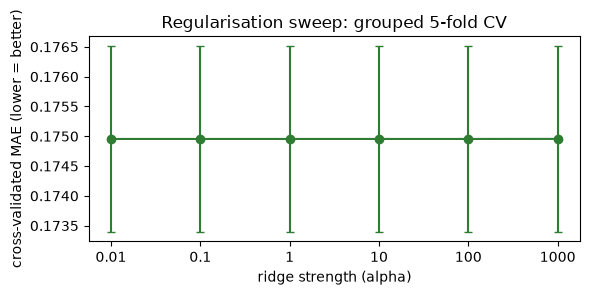

In [13]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(range(len(alphas)), sweep["CV MAE (mean)"], yerr=sweep["CV MAE (spread)"], marker="o", color="#2E7D32", capsize=3)
ax.set_xticks(range(len(alphas))); ax.set_xticklabels(alphas)
ax.set_xlabel("ridge strength (alpha)"); ax.set_ylabel("cross-validated MAE (lower = better)")
ax.set_title("Regularisation sweep: grouped 5-fold CV")
plt.tight_layout(); plt.show()

**What the sweep shows (read it honestly).** The cross-validated MAE is about 0.1750 for every alpha from 0.01 to 1000, and the learned weights barely move. So alpha makes no real difference, and the model is **not** overfitting. That is expected here, because it has only *two* inputs and hundreds of thousands of training rows, so there is little room to chase noise. The code picks the lowest-MAE alpha (0.01), but the differences are far smaller than the spread between folds, so any of the small alphas would do. The ridge penalty is a safety measure we have demonstrated rather than a big lever.

In [14]:
model = Ridge(alpha=best_alpha)
model.fit(features(train), np.log2(train["h_true"]))
a, (b, c) = model.intercept_, model.coef_
print(f"alpha = {best_alpha}")
print(f"log2(h) = {a:.3f} + {b:.3f} * sqrt(1+correct) + {c:.3f} * sqrt(1+wrong)")

def half_life_predict(frame):
    return np.clip(np.power(2.0, model.predict(features(frame))), H_MIN, H_MAX)

def model_predict(frame):
    return np.power(2.0, -frame["t_days"] / half_life_predict(frame)).clip(0, 1)

alpha = 0.01
log2(h) = 5.938 + 0.097 * sqrt(1+correct) + -0.603 * sqrt(1+wrong)


**Reading the three numbers:** `b` says how much each past *correct* answer stretches the half-life; `c` says how much each past *wrong* answer changes it (usually it shrinks it). These are the model's learned weights. The hand-written rule had no such numbers learned from data.

## Step 6: Score them on learners the model never saw *(Person C)*
- **MAE (mean absolute error):** on average, how far the guess is from the real recall, on a 0 to 1 scale. **Lower is better.**
- **AUC:** how well the guesses separate "remembered" (recall ≥ 0.5) from "forgot". 0.5 is a coin flip, 1.0 is perfect. **Higher is better.**
- **Half-life correlation:** how closely the predicted half-lives track the real ones (the model and rule both predict one). Higher is better.

In [15]:
from sklearn.metrics import mean_absolute_error, roc_auc_score

methods = {
    "Average guess": average_predict(test),
    "Hand-written rule (baseline)": rule_predict(test).to_numpy(),
    "Half-life regression (model)": model_predict(test).to_numpy(),
}
rule_h = 4.0 * (1.0 + (3.0 * test["history_correct"] / test["history_seen"]) / 3.0)
half_lives = {
    "Hand-written rule (baseline)": rule_h.to_numpy(),
    "Half-life regression (model)": half_life_predict(test),
}

rows = []
for name, pred in methods.items():
    auc = roc_auc_score(test["recalled"], pred) if np.std(pred) > 0 else 0.5
    cor = np.nan
    if name in half_lives:
        cor = np.corrcoef(half_lives[name], test["h_true"])[0, 1]
    rows.append({"Method": name,
                 "MAE (lower=better)": mean_absolute_error(test["p_recall"], pred),
                 "AUC (higher=better)": auc,
                 "Half-life correlation": cor})
results = pd.DataFrame(rows).set_index("Method").round(4)
results

,MAE (lower=better),AUC (higher=better),Half-life correlation
Method,,,
Average guess,0.1907,0.5000,NaN
Hand-written rule (baseline),0.2778,0.5381,0.0587
Half-life regression (model),0.1714,0.5445,0.0899


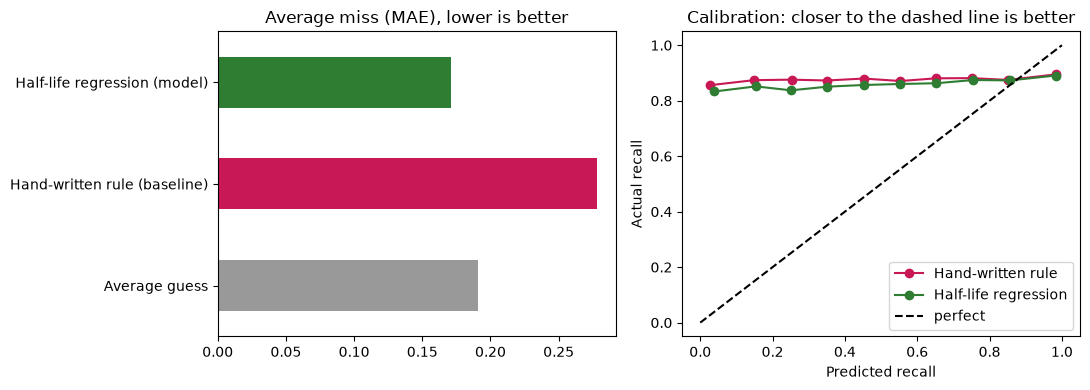

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

results["MAE (lower=better)"].plot.barh(ax=ax[0], color=["#999999", "#C81856", "#2E7D32"])
ax[0].set_title("Average miss (MAE), lower is better")
ax[0].set_ylabel("")

# calibration: when the model says X% recall, how often did people actually recall?
bins = np.linspace(0, 1, 11)
for name, colour in [("Hand-written rule (baseline)", "#C81856"), ("Half-life regression (model)", "#2E7D32")]:
    pred = methods[name]
    which = np.digitize(pred, bins[1:-1])
    xs, ys = [], []
    for k in range(10):
        m = which == k
        if m.sum() > 200:
            xs.append(pred[m].mean()); ys.append(test["p_recall"].to_numpy()[m].mean())
    ax[1].plot(xs, ys, marker="o", label=name.split(" (")[0], color=colour)
ax[1].plot([0, 1], [0, 1], "--", color="black", label="perfect")
ax[1].set_xlabel("Predicted recall"); ax[1].set_ylabel("Actual recall")
ax[1].set_title("Calibration: closer to the dashed line is better")
ax[1].legend()
plt.tight_layout(); plt.show()

**How to read the charts.** Left: the shorter the bar, the smaller the average mistake. Right: if the model says "80% likely to remember", then about 80% of those cases should actually be remembered. A line hugging the dashed diagonal means the guesses are honest.

## Step 7: Is the gap real or luck? *(Person C)*
A single score could be a fluke. We re-score on 20 random resamples of the test rows and check that the model's error is lower in every one (a simple *bootstrap*: re-shuffle, re-measure, count).

In [17]:
rng = np.random.default_rng(SEED)
y = test["p_recall"].to_numpy()
rule_p, model_p = methods["Hand-written rule (baseline)"], methods["Half-life regression (model)"]

wins, diffs = 0, []
for _ in range(20):
    i = rng.integers(0, len(y), len(y))
    diff = np.abs(y[i] - rule_p[i]).mean() - np.abs(y[i] - model_p[i]).mean()   # >0 means model better
    diffs.append(diff); wins += diff > 0
print(f"Model beat the rule in {wins}/20 resamples. Average MAE improvement: {np.mean(diffs):.4f}")

Model beat the rule in 20/20 resamples. Average MAE improvement: 0.1063


## Step 8: Further validation (planned) *(Person C)*
Brief item 4 says a description is enough at this stage. Our plan follows figure 6 of the CS231n report linked in the brief: take several models, push them through **the same pipeline** (same cleaned data, same learner-held-out split, same scores), and put the scores side by side. If a simple model and a flexible model agree on the ranking, we trust the ranking more.

| Model | Why it is in the comparison |
|---|---|
| Always guess the average | The floor. Anything useful must beat it. |
| Hand-written rule | The current Kumbuka baseline. |
| **Half-life regression (base model)** | What we built above. |
| Logistic regression | A standard yes/no model on the same inputs. It predicts "remembered or not" directly, so it checks whether the half-life idea is adding anything. |
| Random forest regressor | A flexible model that can find patterns the half-life formula cannot. It shows how much room is left above our model. |

**Same scores for all:** MAE, AUC and a calibration curve (does "80%" really mean 80%?). We will also add *log-loss*, which punishes confident wrong guesses.

**A second-dataset check already run.** We repeated the rule vs half-life regression vs logistic regression comparison on **Anki review logs** (`anki_experiment.py`, 40 learners, about 1.04 million reviews, split by learner). A different app and a different kind of learner, so it tests whether the ranking holds up.

| Anki test set (12 held-out learners) | MAE | AUC | Log-loss |
|---|---|---|---|
| Always guess the average | 0.320 | 0.500 | 0.562 |
| Hand-written rule | 0.487 | 0.484 | 1.527 |
| Half-life regression | 0.273 | 0.604 | 0.783 |
| Logistic regression | 0.312 | 0.702 | 0.499 |

What it tells us: half-life regression beat the hand-written rule on MAE and AUC again, and for 12 of 12 test learners, but it was **overconfident** (log-loss worse than the plain average), and logistic regression had the best AUC and log-loss. So "learned beats hand-written" held up on a second dataset, while "half-life regression is the best learned model" did not. We will say that plainly in the final notebook.

**Other checks still to do:** repeat the 80/20 split with several seeds and report the spread; and, once the app has real student data, test on it (the Research Methodology study).

## Step 9: Save the model for the app *(Person C)*
The model is just three numbers plus two limits, so it can live inside the phone app. We save them to `kumbuka_hlr_v1.json`. A later step replaces `placeholder-v1` in Kumbuka's `RecallPredictor` with this file. Nothing about it needs the internet.

In [18]:
import json

export = {
    "version": "hlr-v1",
    "formula": "log2(h_days) = intercept + w_correct*sqrt(1+correct) + w_wrong*sqrt(1+wrong); p = 2^(-t_days/h_days)",
    "intercept": float(model.intercept_),
    "w_correct": float(model.coef_[0]),
    "w_wrong": float(model.coef_[1]),
    "h_min_days": H_MIN,
    "h_max_days": H_MAX,
    "ridge_alpha": float(best_alpha),
    "trained_on": "Duolingo half-life regression release, 1M-row sample, learner-held-out split, seed 42",
}
with open("kumbuka_hlr_v1.json", "w") as f:
    json.dump(export, f, indent=2)
print(json.dumps(export, indent=2))

{
  "version": "hlr-v1",
  "formula": "log2(h_days) = intercept + w_correct*sqrt(1+correct) + w_wrong*sqrt(1+wrong); p = 2^(-t_days/h_days)",
  "intercept": 5.938361999953164,
  "w_correct": 0.09741891008618403,
  "w_wrong": -0.602679947698708,
  "h_min_days": 0.010416666666666666,
  "h_max_days": 274.0,
  "ridge_alpha": 0.01,
  "trained_on": "Duolingo half-life regression release, 1M-row sample, learner-held-out split, seed 42"
}


## Step 10: Conclusion and honest limits *(Person C)*
**Result against H0.** *(Fill in your own sentence after reading the table above: did the model's MAE beat the rule's? By how much? Did AUC agree? Did the bootstrap agree?)*

**What this does and does not show.**
1. **Duolingo marks answers automatically; Kumbuka relies on the student rating themselves.** A model trained on objective right/wrong may behave differently on honesty-dependent ratings. This is the central threat to validity (see `DESIGN.md` §8).
2. **A Duolingo word is reviewed dozens of times; a university topic may be reviewed 5 to 8 times a semester.** The model learns from rich histories and will have thin ones in the app.
3. **Cold start.** With no history there is nothing to predict from. The app's baseline formula covers a topic's first few reviews.
4. **The rule's rating was a stand-in** (past accuracy × 3), because Duolingo has no self-rating. A different stand-in could shift the rule's score.
5. **The label is a share of answers right in one session**, not a yes/no about a whole topic, so AUC uses a ≥ 0.5 cut-off.
6. **About half of the half-life targets are clipped at the 274-day cap** (Observation 1), and Duolingo reviews are bunched close together (Observation 3). Both limit what the model can learn about long gaps, which is what a university revision schedule needs.
7. **This notebook compares guesses about memory, not revision outcomes.** Whether better guesses actually help students score higher is the separate Research Methodology study (paired comparison of two sets of topics per student).

**Sustainable AI.** The model is three numbers and runs on the phone, so it needs no server and uses almost no energy once trained.